# Lab 08 — Indexing with Trees
**Tree-based indexes for (approximate) nearest-neighbour search: KD-tree, Ball tree, VP-tree, Annoy**

In [1]:
!uv tree -d 1

Resolved 221 packages in 20ms
ir v0.1.0
├── altair v6.2.2
├── beautifulsoup4 v4.15.0
├── bs4 v0.0.2
├── feedparser v6.0.14
├── ipykernel v7.3.0
├── matplotlib v3.10.9
├── nltk v3.10.3
├── pandas v2.3.3
├── requests v2.34.2
├── scikit-learn v1.7.2
├── selenium v4.48.0
├── sentence-transformers v6.2.0
└── statsmodels v0.15.0


# Part 1 — Theoretical background

## 1.1 Recap: nearest-neighbour search and brute force
Given a collection $X=\{x_1,\dots,x_n\}\subset\mathbb{R}^d$ and a query $q$, the **k nearest neighbours** are the $k$ vectors with the smallest distance $\lVert q-x_i\rVert_2$.

*Brute force* computes all $n$ distances: $O(nd)$ per query. It is exact but too slow for big $n$.

**Idea of space-partitioning indexes:** pre-organise the data into a **tree** so that, for a query, whole groups of points can be **discarded without computing any distance** to them. This is the same idea as a binary search tree or a B-tree, applied to points in space.

All trees in this lab follow the same pattern:

| | |
|---|---|
| **Build** | recursively split the points into two groups until groups are small (a *leaf* holds a few points) |
| **Query** | descend to the leaf where the query falls, collect candidates, then *backtrack*, visiting another branch **only if it could still contain a closer point** (pruning) |

They differ in **how they split** and therefore in **how they prune**.

## 1.2 KD-tree (k-dimensional tree)
**Build.** At each node choose one coordinate (axis) — cycling through axes, or the axis with the largest spread — and split the points at the **median** of that coordinate. Points with a smaller value go to the left child, the others to the right child. Recurse.

**Query (1-NN).**
1. Descend: at a node splitting on axis $a$ at value $s$, go left if $q_a<s$ else right.
2. At a leaf, compute the distances to its points; keep the best distance so far, $\tau$.
3. Backtrack: for every node on the path, the *other* side can contain a better point only if the splitting line is closer than $\tau$:
$$|q_a - s| < \tau.$$
Otherwise that whole subtree is **pruned**.

*Example.* Points $A(2,3), B(5,4), C(9,6), D(4,7), E(8,1), F(7,2)$, query $q=(9,2)$. The root splits on $x=7$. Suppose the best point found is $E(8,1)$ with $\tau=\sqrt2\approx1.41$. The distance from $q$ to the line $x=7$ is $|9-7|=2>1.41$, so **the entire left half $\{A,B,D\}$ is skipped** without computing a single distance. The code below shows this on a real tree.

Strength: simple, fast in **low dimension** (roughly $d\lesssim 10$–20). Weakness: needs **axis-aligned** splits and the **Euclidean-like** coordinates; in high dimension almost every branch fails the pruning test.

In [ ]:
import numpy as np, heapq, time, random
import matplotlib.pyplot as plt

class SimpleKDTree:
    # KD-tree. Splits on the axis of largest spread, at the median.
    def __init__(self, data, leaf_size=16):
        self.data = np.asarray(data, dtype=float)
        self.leaf_size = leaf_size
        self.root = self._build(np.arange(len(self.data)))
    def _build(self, idx):
        if len(idx) <= self.leaf_size:
            return ("leaf", idx)
        pts = self.data[idx]
        axis = int(np.argmax(pts.max(0) - pts.min(0)))
        order = idx[np.argsort(pts[:, axis])]
        mid = len(order) // 2
        split = self.data[order[mid], axis]
        return ("node", axis, split, self._build(order[:mid]), self._build(order[mid:]))
    def query(self, q, k=1):
        # returns (ids, distances, number_of_distance_computations, visited_leaf_points)
        q = np.asarray(q, dtype=float)
        heap, self.n_dist, self.visited = [], 0, []      # max-heap of (-dist, id)
        def visit(node):
            if node[0] == "leaf":
                idx = node[1]
                d = np.linalg.norm(self.data[idx] - q, axis=1)
                self.n_dist += len(idx); self.visited.extend(idx.tolist())
                for di, i in sorted(zip(d.tolist(), idx.tolist())):
                    if len(heap) < k: heapq.heappush(heap, (-di, i))
                    elif di < -heap[0][0]: heapq.heapreplace(heap, (-di, i))
                    else: break
                return
            _, axis, split, left, right = node
            diff = q[axis] - split
            near, far = (left, right) if diff < 0 else (right, left)
            visit(near)
            if len(heap) < k or abs(diff) < -heap[0][0]:     # PRUNING RULE
                visit(far)
        visit(self.root)
        res = sorted((-nd, i) for nd, i in heap)
        return [i for _, i in res], [d for d, _ in res], self.n_dist, self.visited


P = np.array([[2, 3], [5, 4], [9, 6], [4, 7], [8, 1], [7, 2]], dtype=float)
names = "ABCDEF"
t = SimpleKDTree(P, leaf_size=1)
ids, dists, n_dist, visited = t.query([9, 2], k=1)
print("nearest:", names[ids[0]], "distance:", round(dists[0], 3))
print("points whose distance was computed:", [names[i] for i in visited], f"({n_dist} of {len(P)})")

nearest: E distance: 1.414
points whose distance was computed: ['F', 'E'] (2 of 6)


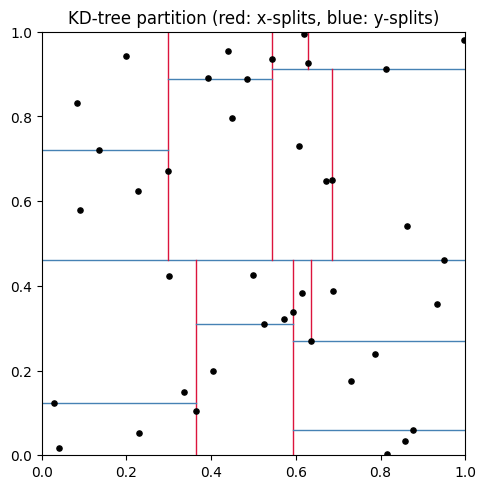

In [4]:
def plot_kd_partition(points, leaf_size=3, ax=None):
    # draw the rectangular cells created by a KD-tree
    ax = ax or plt.gca()
    pts = np.asarray(points)
    def rec(idx, x0, x1, y0, y1):
        if len(idx) <= leaf_size: return
        p = pts[idx]; axis = int(np.argmax(p.max(0) - p.min(0)))
        order = idx[np.argsort(p[:, axis])]; mid = len(order) // 2
        s = pts[order[mid], axis]
        if axis == 0:
            ax.plot([s, s], [y0, y1], c="crimson", lw=1); rec(order[:mid], x0, s, y0, y1); rec(order[mid:], s, x1, y0, y1)
        else:
            ax.plot([x0, x1], [s, s], c="steelblue", lw=1); rec(order[:mid], x0, x1, y0, s); rec(order[mid:], x0, x1, s, y1)
    rec(np.arange(len(pts)), 0, 1, 0, 1)
    ax.scatter(*pts.T, s=14, c="black", zorder=3); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")

rng0 = np.random.default_rng(0)
small = rng0.random((40, 2))
plt.figure(figsize=(5.5, 5.5)); plot_kd_partition(small); plt.title("KD-tree partition (red: x-splits, blue: y-splits)"); plt.show()

## 1.3 Ball tree
**Build.** Each node stores a **ball** (a centre $c$ and a radius $r$) that contains all points of its subtree. To split, pick two far-apart points, assign every point to the closer one, and recurse on the two groups.

**Query — pruning rule.** For a ball with centre $c$ and radius $r$, no point inside can be closer to $q$ than
$$\lVert q-c\rVert - r .$$
If this lower bound is larger than the best distance found so far $\tau$, the **whole ball is skipped**.

Compared with KD-trees, balls do not need axis-aligned splits and adapt better to data that is clustered or lies on a lower-dimensional surface, so they degrade a bit more gracefully in higher dimension. They work with any metric (the pruning uses only the triangle inequality). The price is a more expensive build.

## 1.4 Vantage-Point tree (VP-tree)
A **metric tree**: it only needs a distance function $d(\cdot,\cdot)$ that satisfies the triangle inequality — no coordinates at all (strings with edit distance, sets with Jaccard distance, …).

**Build.** Choose a *vantage point* $v$, compute the distance of every point to $v$, and let $\mu$ be the **median** distance. Points with $d\le\mu$ go *inside*, the others *outside*. Recurse.

**Query — pruning via the triangle inequality.** Let $\tau$ be the current best distance and $d_{qv}=d(q,v)$.
* visit *inside* only if $d_{qv}-\tau\le\mu$
* visit *outside* only if $d_{qv}+\tau\ge\mu$

*Example.* $\mu=5$, $d_{qv}=9$, $\tau=2$. Inside is visited only if $9-2=7\le5$ → **false, the entire inside is pruned**. Outside is visited since $9+2=11\ge5$.

## 1.5 Random-projection trees and Annoy
Exact trees degrade in high dimension, so **Annoy** (Approximate Nearest Neighbours Oh Yeah, used at Spotify) gives up exactness:

**Build one tree.** Pick two random points $a,b$ of the node; the splitting hyperplane is the **set of points equidistant from $a$ and $b$** (normal vector $a-b$). Points on one side go left, the others right. Recurse until a leaf holds few points. The hyperplane is *not* axis-aligned and adapts to the data.

**Query.** Keep one **priority queue** across all trees, ordered by the distance to the splitting hyperplane (closest margin first). Pop nodes and collect the points of the leaves until at least **`search_k`** candidates were gathered (default `n_trees * n`), then compute the exact distances of the candidates and return the best `n`.

| Knob | Effect |
|---|---|
| `n_trees` ↑ | higher recall, bigger index, slower build |
| `search_k` ↑ | higher recall, slower query (runtime knob, no rebuild) |

The code below contains a compact from-scratch implementation of this idea; later we use the real **Annoy** library when it is installed and fall back to this implementation otherwise.

In [9]:
class SimpleVPTree:
    # Minimal VP-tree (Euclidean). Pure Python on purpose: we will see why that is slow.
    def __init__(self, data, leaf_size=16, seed=0):
        self.data = np.asarray(data, dtype=float); self.leaf_size = leaf_size
        self.rng = np.random.default_rng(seed)
        self.root = self._build(np.arange(len(self.data)))
    def _build(self, idx):
        if len(idx) <= self.leaf_size:
            return ("leaf", idx)
        v = int(idx[self.rng.integers(len(idx))])
        d = np.linalg.norm(self.data[idx] - self.data[v], axis=1)
        order = np.argsort(d); mid = len(idx) // 2
        mu = float(d[order[mid]])
        inside, outside = idx[order[:mid]], idx[order[mid:]]
        return ("node", v, mu, self._build(inside), self._build(outside))
    def query(self, q, k=1):
        q = np.asarray(q, dtype=float); heap = []
        self.n_dist = 0
        def tau(): return -heap[0][0] if len(heap) == k else np.inf
        def visit(node):
            if node[0] == "leaf":
                idx = node[1]; d = np.linalg.norm(self.data[idx] - q, axis=1); self.n_dist += len(idx)
                for di, i in sorted(zip(d.tolist(), idx.tolist())):
                    if len(heap) < k: heapq.heappush(heap, (-di, i))
                    elif di < -heap[0][0]: heapq.heapreplace(heap, (-di, i))
                    else: break
                return
            _, v, mu, inside, outside = node
            dqv = float(np.linalg.norm(self.data[v] - q)); self.n_dist += 1
            first, second = (inside, outside) if dqv <= mu else (outside, inside)
            visit(first)
            if first is inside:                          # now decide whether the other side can still help
                if dqv + tau() >= mu: visit(second)
            else:
                if dqv - tau() <= mu: visit(second)
        visit(self.root)
        res = sorted((-nd, i) for nd, i in heap)
        return [i for _, i in res], [d for d, _ in res]


class SimpleRPForest:
    # Annoy-like random-projection forest with the same small API as annoy.AnnoyIndex (euclidean only).
    def __init__(self, f, metric="euclidean"):
        assert metric in ("euclidean", "angular"); self.f, self.metric = f, metric
        self.items = {}
    def add_item(self, i, v): self.items[i] = np.asarray(v, dtype=float)
    def _prep(self, X): return X / np.maximum(np.linalg.norm(X, axis=-1, keepdims=True), 1e-12) if self.metric == "angular" else X
    def build(self, n_trees, leaf_size=None, seed=0):
        ids = np.array(sorted(self.items)); self.ids = ids
        self.X = self._prep(np.vstack([self.items[i] for i in ids]))
        self.leaf = leaf_size or max(self.f + 2, 16)
        rng = np.random.default_rng(seed); self.trees = []
        for _ in range(n_trees):
            nodes = []                                        # node = ("leaf", idx) or ("split", normal, offset, left, right)
            stack = [(np.arange(len(ids)), None, None)]       # (indices, parent_node_id, side)
            while stack:
                idx, parent, side = stack.pop()
                nid = len(nodes); nodes.append(None)
                if parent is not None: nodes[parent][3 if side == 0 else 4] = nid
                if len(idx) <= self.leaf:
                    nodes[nid] = ("leaf", idx); continue
                a, b = self.X[rng.choice(idx, 2, replace=False)]
                normal = a - b; offset = -float(normal @ (a + b)) / 2
                margin = self.X[idx] @ normal + offset
                left_mask = margin < 0
                if left_mask.all() or (~left_mask).all():     # degenerate: random split
                    left_mask = rng.random(len(idx)) < 0.5
                    if left_mask.all() or (~left_mask).all(): left_mask[0] = ~left_mask[0]
                nodes[nid] = ["split", normal, offset, None, None]
                stack.append((idx[left_mask], nid, 0)); stack.append((idx[~left_mask], nid, 1))
            self.trees.append(nodes)
    def get_nns_by_vector(self, v, n, search_k=-1, include_distances=False):
        v = self._prep(np.asarray(v, dtype=float))
        if search_k == -1: search_k = n * len(self.trees)
        pq = [(-np.inf, t, 0) for t in range(len(self.trees))]; heapq.heapify(pq)
        cand = []; seen = 0
        while pq and seen < search_k:
            prio, t, nid = heapq.heappop(pq); node = self.trees[t][nid]
            if node[0] == "leaf":
                cand.append(node[1]); seen += len(node[1]); continue
            _, normal, offset, left, right = node
            margin = float(normal @ v + offset); d = -prio
            heapq.heappush(pq, (-min(d, margin), t, right)); heapq.heappush(pq, (-min(d, -margin), t, left))
        cand = np.unique(np.concatenate(cand)) if cand else np.array([], dtype=int)
        dist = np.linalg.norm(self.X[cand] - v, axis=1); order = np.argsort(dist)[:n]
        out = self.ids[cand[order]].tolist()
        return (out, dist[order].tolist()) if include_distances else out

In [10]:
# quick sanity check of both from-scratch trees against brute force
rng = np.random.default_rng(1)
Xs = rng.random((3000, 2)); qs = rng.random((20, 2)); k = 10
exact = [np.argsort(np.linalg.norm(Xs - q, axis=1))[:k] for q in qs]
vp = SimpleVPTree(Xs); kd = SimpleKDTree(Xs)
print("KD-tree exact:", all(set(kd.query(q, k)[0]) == set(e) for q, e in zip(qs, exact)))
print("VP-tree exact:", all(set(vp.query(q, k)[0]) == set(e) for q, e in zip(qs, exact)))
rp = SimpleRPForest(2)
for i, x in enumerate(Xs): rp.add_item(i, x)
rp.build(10)
rec = np.mean([len(set(rp.get_nns_by_vector(q, k)) & set(e)) / k for q, e in zip(qs, exact)])
print(f"RP-forest (10 trees) recall@{k}: {rec:.2f}  (approximate, so below 1.0 is expected)")

KD-tree exact: True
VP-tree exact: True
RP-forest (10 trees) recall@10: 1.00  (approximate, so below 1.0 is expected)


## 1.6 The curse of dimensionality for trees
Pruning works because the *splitting line is farther than the current best distance*. In high dimension distances **concentrate**: the nearest and the farthest point are almost equally far, so the best distance $\tau$ is large compared with the distance to any splitting hyperplane and **nothing can be pruned** — the tree visits (almost) every leaf, so its advantage over brute force vanishes (and its bookkeeping becomes pure overhead).

Let us measure it with our KD-tree: the fraction of the collection whose distance is computed for a 10-NN query.

 dimension | % of points examined (KD-tree, 10-NN, n=20000)
         2 |    0.3%
         5 |    3.3%
        10 |   75.4%
        20 |  100.0%
        50 |  100.0%
       100 |  100.0%


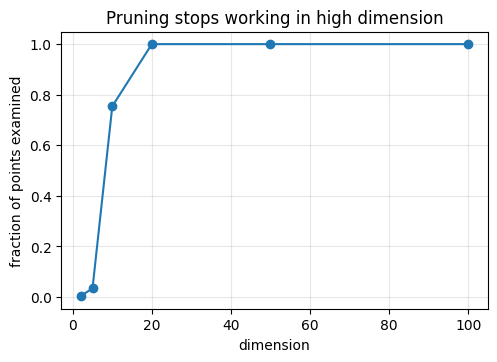

In [11]:
rng = np.random.default_rng(2)
rows = []
for d in [2, 5, 10, 20, 50, 100]:
    X = rng.random((20000, d)); Q = rng.random((20, d))
    tree = SimpleKDTree(X, leaf_size=16)
    frac = np.mean([tree.query(q, 10)[2] / len(X) for q in Q])
    rows.append((d, frac))
print(f"{'dimension':>10} | % of points examined (KD-tree, 10-NN, n=20000)")
for d, f in rows: print(f"{d:>10} | {100 * f:6.1f}%")
plt.figure(figsize=(5.5, 3.6)); plt.plot(*zip(*rows), "o-"); plt.xlabel("dimension"); plt.ylabel("fraction of points examined"); plt.title("Pruning stops working in high dimension"); plt.grid(alpha=.3); plt.show()

## 1.7 Summary of the structures

| Structure | Exact? | Needs | Split | Pruning rule | Typical use |
|---|---|---|---|---|---|
| KD-tree | yes | coordinates, Euclidean-like | axis-aligned median | distance to splitting line $<\tau$ | low-dimensional data (geo, graphics) |
| Ball tree | yes | any metric | clusters → balls | $\lVert q-c\rVert-r<\tau$ | moderate dimension, clustered data |
| VP-tree | yes | any metric (triangle inequality) | median distance to a vantage point | triangle inequality | non-vector objects, custom distances |
| Annoy | **no** | vectors (euclidean/angular/…) | random hyperplane, forest of trees | priority queue + `search_k` | high-dimensional embeddings, read-only static index (memory-mapped file) |

**Quality criteria used in this lab** — for every index we measure: **build time**, **query time** and **recall@N** (the fraction of the true N nearest neighbours that were returned).

# Part 2 — Setup, data, ground truth

## 2.1 Libraries
The cell installs `annoy` if it is missing. If installation is impossible (no compiler / no internet) the notebook **automatically uses the from-scratch `SimpleRPForest` above** under the name `AnnoyIndex`, so every cell still runs (the numbers then describe our implementation, not the C++ library).

In [13]:
!uv add annoy

Resolved 222 packages in 6.50s                                       
Prepared 1 package in 162ms                                                           ⠙ Preparing packages... (0/1)                                                   
Uninstalled 1 package in 104ms
░░░░░░░░░░░░░░░░░░░░ [0/2] Installing wheels...                                 warning: Failed to hardlink files; falling back to full copy. This may lead to degraded performance.
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.
Installed 2 packages in 393ms                               
 + annoy==1.17.3
 ~ ir==0.1.0 (from file:///mnt/d/workspace/inno/ir)


In [14]:
import importlib, subprocess, sys

def ensure(pip_name, import_name=None):
    try:
        importlib.import_module(import_name or pip_name)
        return True
    except ImportError:
        print(f"Installing {pip_name} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name], check=False)
        try:
            importlib.import_module(import_name or pip_name); return True
        except ImportError:
            return False

for pkg, imp in [("numpy", None), ("scipy", None), ("pandas", None), ("matplotlib", None), ("scikit-learn", "sklearn")]:
    ensure(pkg, imp)
HAVE_ANNOY = ensure("annoy")
if HAVE_ANNOY:
    from annoy import AnnoyIndex
    print("Using the real Annoy library")
else:
    AnnoyIndex = SimpleRPForest
    print("annoy is not available -> using our SimpleRPForest (same API).")
    print("NOTE: its recall is meaningful, but its timings are NOT representative of the C++ Annoy library (pure Python).")

Using the real Annoy library


In [15]:
import os, time, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import BallTree, KDTree
from scipy.spatial.distance import cdist
warnings.filterwarnings("ignore")
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda it, **kw: it
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

SEED = 42
random.seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# ---- configuration (reduce for a quick first run) ----
N_POINTS   = 30000      # collection size for the 2-D experiments
N_QUERIES  = 200        # query bucket
K          = 1000       # neighbours requested (recall@K)
VP_QUERIES = 200        # VP-tree is pure Python; reduce this if it takes too long
SCAL_DIMS  = [2, 5, 10, 15, 50, 100, 200]
SCAL_N     = 20000      # collection size in the scalability study
SCAL_Q     = 30         # queries in the scalability study
SCAL_K     = 100        # neighbours in the scalability study

## 2.2 Data: uniformly distributed points
The original lab generated points with a slow Python double loop. A uniform sample in the unit cube $[0,1]^D$ is simply `rng.random((N, D))` — one vectorised call.

We create **30 000 two-dimensional points** (easy to plot) and a **bucket of 200 query points**.

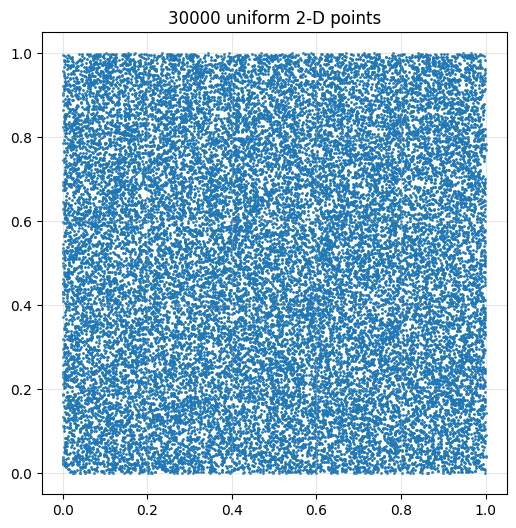

In [16]:
def generate(N, dim, rng=rng):
    # N points uniformly distributed in the unit hypercube [0, 1]^dim
    return rng.random((N, dim))

data2d   = generate(N_POINTS, 2)
bucket2d = generate(N_QUERIES, 2)
plt.figure(figsize=(6, 6)); plt.scatter(data2d[:, 0], data2d[:, 1], s=1); plt.title(f"{N_POINTS} uniform 2-D points"); plt.show()

## 2.3 Ground truth
For every query, the **exact** `K` nearest neighbours by Euclidean distance — computed with vectorised SciPy (`cdist`) instead of a Python double loop (much faster). The tree libraries will be compared against it.

In [17]:
def get_GT(data, bucket, k=K, chunk=100):
    # exact k nearest neighbours of every query (Euclidean), best first -> list of arrays
    gt = []
    for s in range(0, len(bucket), chunk):
        dist = cdist(bucket[s:s + chunk], data)
        part = np.argpartition(dist, min(k, dist.shape[1]) - 1, axis=1)[:, :k]
        order = np.argsort(np.take_along_axis(dist, part, axis=1), axis=1)
        gt.extend(np.take_along_axis(part, order, axis=1))
    return gt

t0 = time.time(); GT = get_GT(data2d, bucket2d); print(f"ground truth for {len(GT)} queries in {time.time() - t0:.2f}s")

ground truth for 200 queries in 0.09s


## 2.4 Recall@N
$$\text{recall@}N=\frac{|\text{result}\cap\text{ground truth}|}{N}$$
Tests: identical lists give 1.0, half of the list gives 0.5, an empty list gives 0.0.

In [18]:
def recall(result, gt, N=K):
    # fraction of the true N nearest neighbours that appear in the result
    return len(set(map(int, result[:N])) & set(map(int, gt[:N]))) / N

def mean_recall(results, gts, N=K):
    return float(np.mean([recall(r, g, N) for r, g in zip(results, gts)]))

b = list(range(1000))
print(recall(b, b, 1000), recall(b[:500], b, 1000), recall([], b, 1000))
assert recall(b, b, 1000) == 1.0 and recall(b[:500], b, 1000) == 0.5 and recall([], b, 1000) == 0.0

1.0 0.5 0.0


In [19]:
def plot_result(points, q=(.5, .5), title=""):
    # the query result drawn over the whole collection
    plt.figure(figsize=(6, 6))
    plt.scatter(data2d[:, 0], data2d[:, 1], s=1, c="lightgray")
    plt.scatter(points[:, 0], points[:, 1], s=3, c="crimson", label=f"{len(points)} results")
    plt.scatter(*q, marker="*", s=200, c="gold", edgecolor="k", label="query"); plt.title(title); plt.legend(loc="upper right"); plt.show()

def evaluate(name, build_fn, query_fn, queries=bucket2d, gts=GT, n=K):
    # build an index, time the queries, return (index, stats)
    t0 = time.time(); index = build_fn(); t_build = time.time() - t0
    t0 = time.time(); res = [query_fn(index, q) for q in queries]; t_query = time.time() - t0
    stats = {"index": name, "build_s": t_build, "query_s_total": t_query, "ms_per_query": 1000 * t_query / len(queries),
             f"recall@{n}": mean_recall(res, gts[:len(queries)], n)}
    print(f"{name:<22} build {t_build:7.3f}s | {stats['ms_per_query']:8.3f} ms/query | recall@{n} = {stats[f'recall@{n}']:.4f}")
    return index, stats

results_table = []

# Part 3 — KD-tree and Ball tree (scikit-learn)
scikit-learn implements both in Cython (compiled C-like code), so they are fast. `tree.query(X, k, return_distance=False)` returns the ids of the `k` nearest neighbours for each row of `X`.

## 3.1 KD-tree

In [20]:
index, st = evaluate("KDTree", lambda: KDTree(data2d),
                     lambda tree, q: tree.query([q], K, return_distance=False)[0])
results_table.append(st); kdtree = index

KDTree                 build   0.020s |    0.316 ms/query | recall@1000 = 1.0000


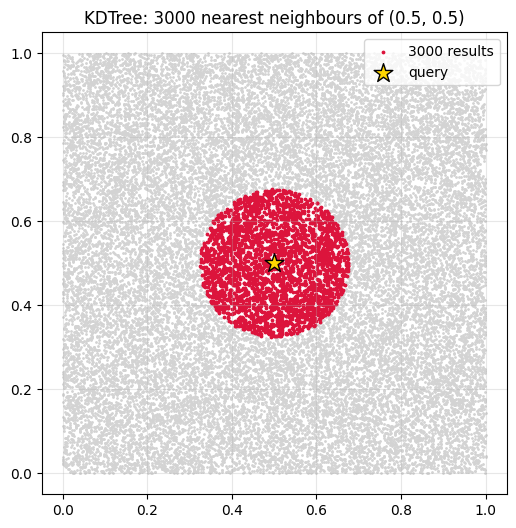

In [21]:
# a sample query: the 3000 nearest neighbours of (0.5, 0.5) form a disc
idx = kdtree.query([(.5, .5)], 3000, return_distance=False)[0]
plot_result(data2d[idx], title="KDTree: 3000 nearest neighbours of (0.5, 0.5)")

**Check.** Recall must be exactly 1.0: KD-trees are *exact* indexes. The only reason to build them is speed. (If a tie in distances happens, recall may be 0.9999…)

## 3.2 Ball tree

BallTree               build   0.016s |    0.340 ms/query | recall@1000 = 1.0000


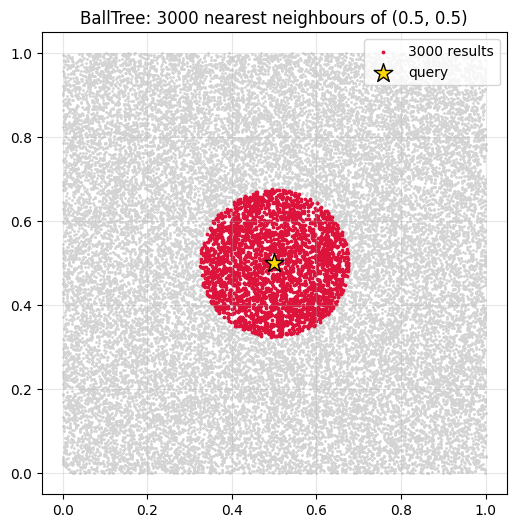

In [22]:
index, st = evaluate("BallTree", lambda: BallTree(data2d),
                     lambda tree, q: tree.query([q], K, return_distance=False)[0])
results_table.append(st); balltree = index
idx = balltree.query([(.5, .5)], 3000, return_distance=False)[0]
plot_result(data2d[idx], title="BallTree: 3000 nearest neighbours of (0.5, 0.5)")

In [23]:
# baseline for reference: brute force with NumPy
def brute_build(): return data2d
def brute_query(X, q):
    d = np.linalg.norm(X - q, axis=1); return np.argpartition(d, K)[:K]
_, st = evaluate("brute force (NumPy)", brute_build, brute_query); results_table.append(st)

brute force (NumPy)    build   0.000s |    1.098 ms/query | recall@1000 = 1.0000


# Part 4 — Annoy
`AnnoyIndex(f, metric)` — `f` is the vector dimension. Add each vector with `add_item(i, v)`, call `build(n_trees)` once (after that no more items can be added), and query with `get_nns_by_vector(v, n, search_k=-1)`.

## 4.1 A single tree

Annoy, 1 tree          build   0.080s |    0.262 ms/query | recall@1000 = 0.9172


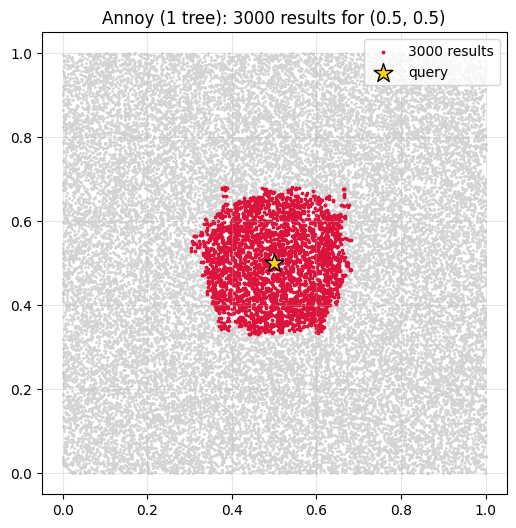

In [24]:
def build_annoy(n_trees, data=data2d, metric="euclidean"):
    index = AnnoyIndex(data.shape[1], metric)
    for i, v in enumerate(data):
        index.add_item(i, v)
    index.build(n_trees)
    return index

annoy1, st = evaluate("Annoy, 1 tree", lambda: build_annoy(1), lambda ix, q: ix.get_nns_by_vector(q, K))
results_table.append(st)
idx = annoy1.get_nns_by_vector([.5, .5], 3000)
plot_result(data2d[idx], title=f"Annoy (1 tree): {len(idx)} results for (0.5, 0.5)")

With a single tree the result is only an **approximation**: the number of returned points can even be smaller than requested, and the returned set is not a clean disc — whole leaves of the tree are missing near split lines.

## 4.2 Many trees

Annoy, 3 trees         build   0.088s |    0.610 ms/query | recall@1000 = 0.9786


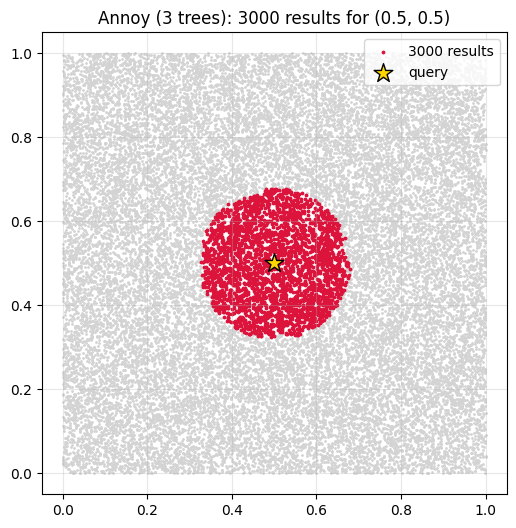

In [25]:
annoy3, st = evaluate("Annoy, 3 trees", lambda: build_annoy(3), lambda ix, q: ix.get_nns_by_vector(q, K))
results_table.append(st)
idx = annoy3.get_nns_by_vector([.5, .5], 3000)
plot_result(data2d[idx], title=f"Annoy (3 trees): {len(idx)} results for (0.5, 0.5)")

### The two knobs: `n_trees` and `search_k`
`search_k` can be changed per query without rebuilding, `n_trees` needs a rebuild.

In [26]:
rows = []
for n_trees in [1, 3, 10, 30]:
    ix = build_annoy(n_trees)
    for mult in [1, 5]:
        sk = K * n_trees * mult
        t0 = time.time(); res = [ix.get_nns_by_vector(q, K, search_k=sk) for q in bucket2d[:100]]; dt = time.time() - t0
        rows.append({"n_trees": n_trees, "search_k": sk, "ms/query": 1000 * dt / 100, f"recall@{K}": mean_recall(res, GT[:100], K)})
print(pd.DataFrame(rows).round(4).to_string(index=False))

 n_trees  search_k  ms/query  recall@1000
       1      1000    0.2633       0.9182
       1      5000    1.1949       1.0000
       3      3000    0.5864       0.9784
       3     15000    2.6270       1.0000
      10     10000    1.7668       0.9988
      10     50000    8.3635       1.0000
      30     30000    5.2685       1.0000
      30    150000   26.1011       1.0000


# Part 5 — Vantage-Point tree
The usual Python package for this is `vptree`, which is written in pure Python. To avoid an extra dependency and to see the algorithm, we use our own `SimpleVPTree` (same idea, also pure Python, leaves with up to 16 points). It is slower than the compiled trees; if it is too slow on your machine, reduce `VP_QUERIES`.

VP-tree (pure Python)  build   0.057s |    4.337 ms/query | recall@1000 = 1.0000


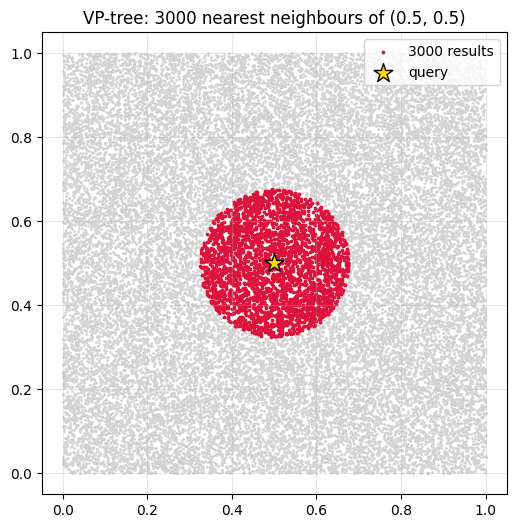

In [27]:
vp_idx, st = evaluate("VP-tree (pure Python)", lambda: SimpleVPTree(data2d, leaf_size=16),
                      lambda t, q: t.query(q, K)[0], queries=bucket2d[:VP_QUERIES], gts=GT)
results_table.append(st); vptree = vp_idx
idx = vptree.query([.5, .5], 3000)[0]
plot_result(data2d[idx], title="VP-tree: 3000 nearest neighbours of (0.5, 0.5)")

In [28]:
summary = pd.DataFrame(results_table)
summary.round(4)

,index,build_s,query_s_total,ms_per_query,recall@1000
0,KDTree,0.0196,0.0633,0.3163,1.0000
1,BallTree,0.0159,0.0680,0.3398,1.0000
2,brute force (NumPy),0.0000,0.2195,1.0975,1.0000
3,"Annoy, 1 tree",0.0802,0.0524,0.2618,0.9172
4,"Annoy, 3 trees",0.0883,0.1221,0.6103,0.9786
5,VP-tree (pure Python),0.0572,0.8673,4.3366,1.0000


# Part 6 — Scalability: varying the dimension
We now increase the dimension `D` and expect trees to **lose speed** (and Annoy to lose recall). `VPTree` is left out (too slow). We test **KDTree**, **BallTree**, **Annoy with 20 trees** and **Annoy with 100 trees**, and brute force as a reference. Data: `SCAL_N` uniform points in `[0,1]^D`, `SCAL_Q` queries, `SCAL_K` neighbours.

> This cell takes a few minutes (longer with the pure-Python Annoy fallback). Reduce `SCAL_DIMS` or `SCAL_N` for a quick run. Brute force here is the vectorised `cdist` version, a fair reference for batch queries.

In [29]:
def run_scalability():
    stats = []
    def add(D, name, t_build, t_search, rec):
        stats.append({"D": D, "index": name, "construction": t_build, "search": t_search, "recall": rec})
    for D in tqdm(SCAL_DIMS, desc="dimensions"):
        data = generate(SCAL_N, D); bucket = generate(SCAL_Q, D)
        gt = get_GT(data, bucket, SCAL_K)

        for name, Tree in [("KDTree", KDTree), ("BallTree", BallTree)]:
            t0 = time.time(); tree = Tree(data); tb = time.time() - t0
            t0 = time.time(); r = tree.query(bucket, SCAL_K, return_distance=False); ts = time.time() - t0
            add(D, name, tb, ts, mean_recall(r, gt, SCAL_K))

        for n_trees in (20, 100):
            t0 = time.time(); ix = build_annoy(n_trees, data); tb = time.time() - t0
            t0 = time.time(); r = [ix.get_nns_by_vector(q, SCAL_K) for q in bucket]; ts = time.time() - t0
            add(D, f"Annoy {n_trees} trees", tb, ts, mean_recall(r, gt, SCAL_K))

        t0 = time.time(); r = np.argpartition(cdist(bucket, data), SCAL_K, axis=1)[:, :SCAL_K]; ts = time.time() - t0   # vectorised brute force
        add(D, "brute force", 0.0, ts, mean_recall(r, gt, SCAL_K))
    return pd.DataFrame(stats)

df = run_scalability()
df.to_csv("scalability_results.csv", index=False)
df.round(4)

dimensions: 100%|██████████| 7/7 [00:08<00:00,  1.24s/it]


,D,index,construction,search,recall
0,2,KDTree,0.0057,0.0010,1.0000
1,2,BallTree,0.0062,0.0012,1.0000
2,2,Annoy 20 trees,0.2452,0.0107,1.0000
3,2,Annoy 100 trees,1.3311,0.0598,1.0000
4,2,brute force,0.0000,0.0041,1.0000
5,5,KDTree,0.0138,0.0020,1.0000
6,5,BallTree,0.0087,0.0037,1.0000
7,5,Annoy 20 trees,0.1575,0.0113,0.9993
8,5,Annoy 100 trees,0.7974,0.0547,1.0000
9,5,brute force,0.0000,0.0044,1.0000


## 6.1 Plots
Look at the graphs and discuss which data structure you would choose, and for which task:
* computer graphics and geospatial data?  * text embeddings?  * volatile data (many inserts/updates)?  * stable data?  * web search?  * a library catalogue?

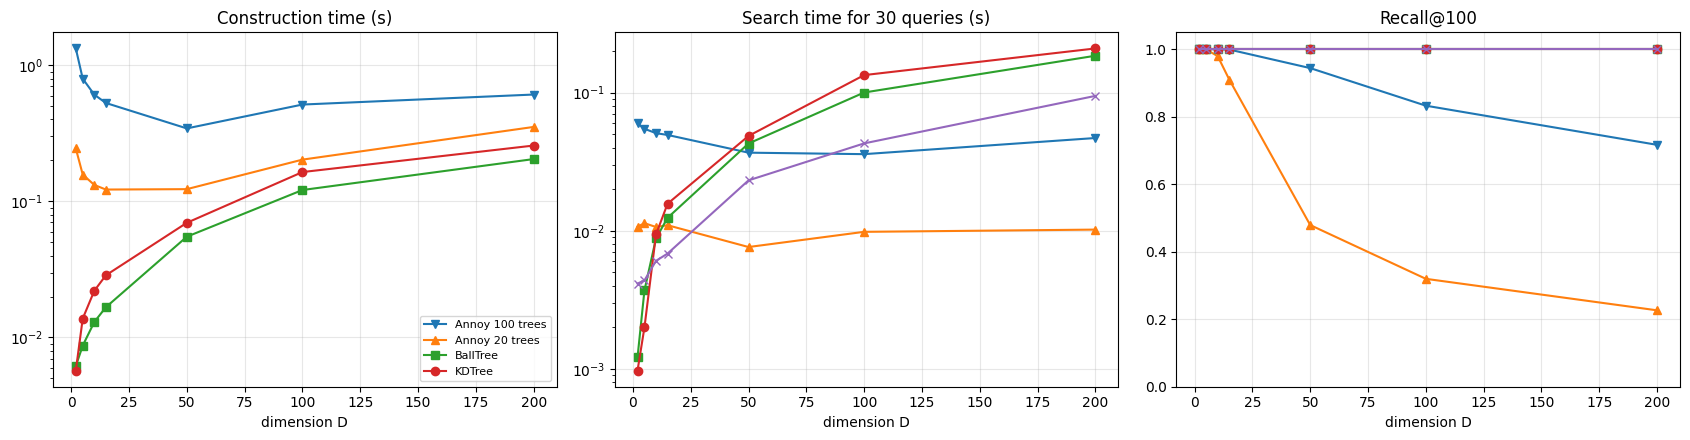

In [30]:
markers = {"KDTree": "o", "BallTree": "s", "Annoy 20 trees": "^", "Annoy 100 trees": "v", "brute force": "x"}
panels = [("construction", "Construction time (s)", True), ("search", f"Search time for {SCAL_Q} queries (s)", True), ("recall", f"Recall@{SCAL_K}", False)]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (col, title, logy) in zip(axes, panels):
    for name, g in df.groupby("index"):
        if col == "construction" and name == "brute force": continue
        g = g.sort_values("D"); ax.plot(g["D"], g[col], marker=markers.get(name, "o"), label=name)
    ax.set_title(title); ax.set_xlabel("dimension D")
    if logy: ax.set_yscale("log")
    if col == "recall": ax.set_ylim(0, 1.05)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

In [31]:
# Speed relative to brute force (values below 1 = faster than brute force)
piv = df.pivot(index="D", columns="index", values="search")
(piv.div(piv["brute force"], axis=0).drop(columns="brute force")).round(2)

index,Annoy 100 trees,Annoy 20 trees,BallTree,KDTree
D,,,,
2,14.42,2.58,0.29,0.23
5,12.52,2.59,0.85,0.46
10,8.40,1.76,1.45,1.55
15,7.22,1.60,1.81,2.29
50,1.59,0.33,1.85,2.10
100,0.84,0.23,2.34,3.12
200,0.50,0.11,1.95,2.21
